<a href="https://colab.research.google.com/github/mahmoud-elmowafy/breast-cancer-svm-classification-regression/blob/main/breast_cancer_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("wasiqaliyasir/breast-cancer-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'breast-cancer-dataset' dataset.
Path to dataset files: /kaggle/input/breast-cancer-dataset


In [ ]:
import os

data_path = "/kaggle/input/breast-cancer-dataset"

for file in os.listdir(data_path):
    print(file)

Breast_cancer_dataset.csv


In [ ]:
import pandas as pd

file_path = "/kaggle/input/breast-cancer-dataset/Breast_cancer_dataset.csv"

df = pd.read_csv(file_path)

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Info:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())

Dataset Shape: (569, 33)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null   

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN



Columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Missing Values:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se            

In [ ]:
# Create a copy
df_clean = df.copy()

# Drop unnecessary columns
df_clean.drop(columns=['id', 'Unnamed: 32'], inplace=True)

# Check missing values
print("Missing Values:")
print(df_clean.isnull().sum().sum())

# Check duplicates
print("\nDuplicates:", df_clean.duplicated().sum())

# Check dataset shape
print("\nDataset Shape:", df_clean.shape)

# Display first rows
display(df_clean.head())

Missing Values:
0

Duplicates: 0

Dataset Shape: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
print(df_clean['diagnosis'].value_counts())

print("\nPercentages:")
print(df_clean['diagnosis'].value_counts(normalize=True) * 100)

diagnosis
B    357
M    212
Name: count, dtype: int64

Percentages:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


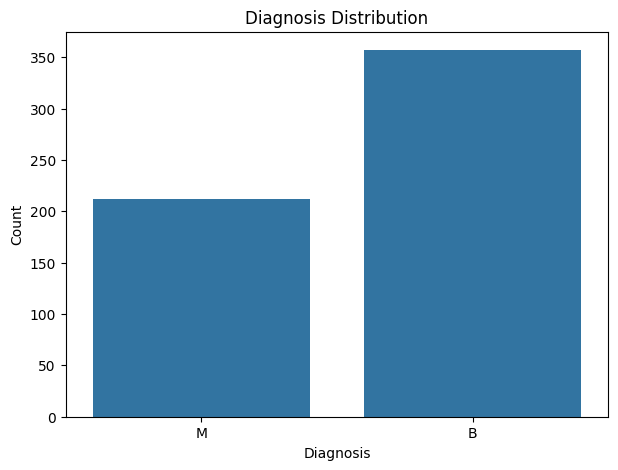

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='diagnosis')

plt.title('Diagnosis Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

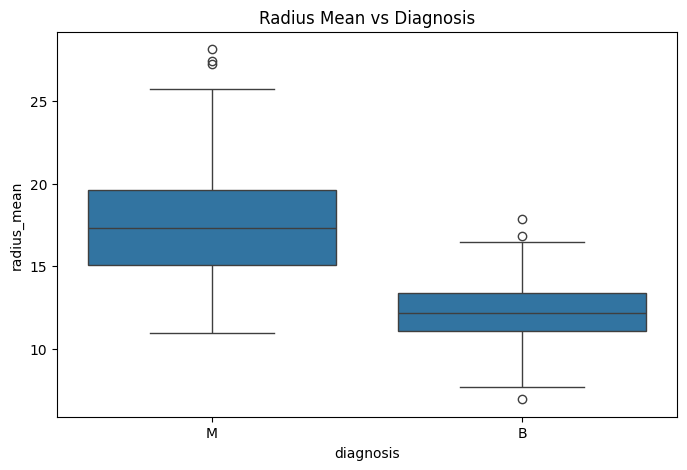

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='diagnosis',
    y='radius_mean'
)

plt.title('Radius Mean vs Diagnosis')
plt.show()

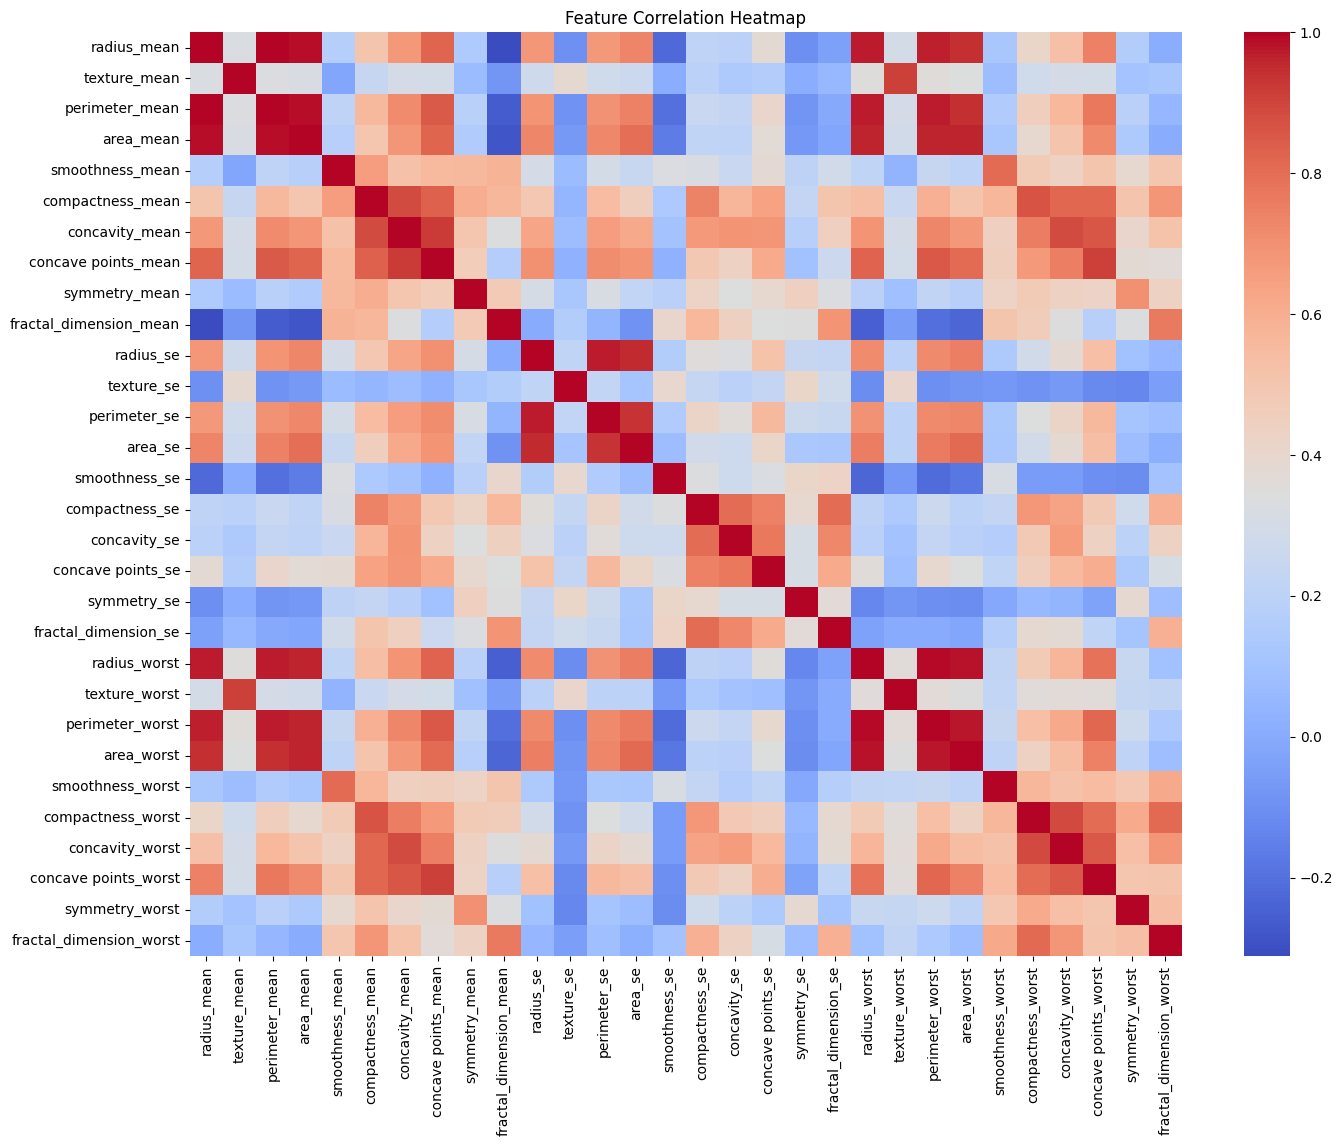

In [ ]:
plt.figure(figsize=(16, 12))

corr = df_clean.drop(columns='diagnosis').corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    annot=False
)

plt.title('Feature Correlation Heatmap')
plt.show()

In [ ]:
print(df_clean['diagnosis'].value_counts())

print("\nPercentages:")
print(df_clean['diagnosis'].value_counts(normalize=True) * 100)

diagnosis
B    357
M    212
Name: count, dtype: int64

Percentages:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


In [ ]:
# Define Features and Target
X_class = df_clean.drop(columns=['diagnosis'])
y_class = df_clean['diagnosis'].map({
    'B': 0,
    'M': 1
})

print("Features Shape:", X_class.shape)
print("Target Shape:", y_class.shape)

print("\nTarget Distribution:")
print(y_class.value_counts())

Features Shape: (569, 30)
Target Shape: (569,)

Target Distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


In [ ]:
# Define Features and Target
X_reg = df_clean.drop(columns=['diagnosis', 'radius_mean'])
y_reg = df_clean['radius_mean']

print("Features Shape:", X_reg.shape)
print("Target Shape:", y_reg.shape)

Features Shape: (569, 29)
Target Shape: (569,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Classification Training:", X_train_class.shape)
print("Classification Testing:", X_test_class.shape)

Classification Training: (455, 30)
Classification Testing: (114, 30)


In [ ]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Regression Training:", X_train_reg.shape)
print("Regression Testing:", X_test_reg.shape)

Regression Training: (455, 29)
Regression Testing: (114, 29)


In [ ]:
from sklearn.preprocessing import StandardScaler

# Regression Scaling
scaler_reg = StandardScaler()

X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Regression Scaling Completed!")

Regression Scaling Completed!


In [ ]:
from sklearn.svm import SVR

# Create SVR Model
svr_model = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)

# Train Model
svr_model.fit(X_train_reg_scaled, y_train_reg)

print("SVR Model Trained Successfully!")

SVR Model Trained Successfully!


In [ ]:
y_pred_reg = svr_model.predict(X_test_reg_scaled)

print("Actual Values:")
print(y_test_reg.head(10).values)

print("\nPredicted Values:")
print(y_pred_reg[:10])

Actual Values:
[12.47 18.94 15.46 12.4  11.54 20.6  22.01 17.57 13.34 13.9 ]

Predicted Values:
[12.52665644 19.61198663 15.83179316 11.80093202 11.03808161 17.9991647
 21.43806642 17.65286044 13.01436658 13.93305154]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test_reg, y_pred_reg)

mse = mean_squared_error(y_test_reg, y_pred_reg)

rmse = np.sqrt(mse)

r2 = r2_score(y_test_reg, y_pred_reg)

print("SVR Model Evaluation")
print("--------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

SVR Model Evaluation
--------------------
MAE: 0.5090088151244451
MSE: 1.0729701080180487
RMSE: 1.0358427042838352
R2 Score: 0.9112238454351117


In [ ]:
# Define Features and Target

X_class = df_clean.drop(columns=['diagnosis'])

y_class = df_clean['diagnosis'].map({
    'B': 0,
    'M': 1
})

print("Features Shape:", X_class.shape)
print("Target Shape:", y_class.shape)

print("\nTarget Distribution:")
print(y_class.value_counts())

Features Shape: (569, 30)
Target Shape: (569,)

Target Distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Classification Training:", X_train_class.shape)
print("Classification Testing:", X_test_class.shape)

Classification Training: (455, 30)
Classification Testing: (114, 30)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_class = StandardScaler()

X_train_class_scaled = scaler_class.fit_transform(X_train_class)

X_test_class_scaled = scaler_class.transform(X_test_class)

print("Classification Scaling Completed!")

Classification Scaling Completed!


In [ ]:
from sklearn.svm import SVC

svc_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

svc_model.fit(
    X_train_class_scaled,
    y_train_class
)

print("SVC Model Trained Successfully!")

SVC Model Trained Successfully!


In [ ]:
y_pred_class = svc_model.predict(X_test_class_scaled)

print("Actual Values:")
print(y_test_class.head(10).values)

print("\nPredicted Values:")
print(y_pred_class[:10])

Actual Values:
[0 1 0 1 0 0 1 0 0 0]

Predicted Values:
[0 1 0 0 0 0 1 0 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test_class, y_pred_class))

print("Precision:", precision_score(y_test_class, y_pred_class))

print("Recall:", recall_score(y_test_class, y_pred_class))

print("F1 Score:", f1_score(y_test_class, y_pred_class))

print("\nClassification Report:")

print(classification_report(
    y_test_class,
    y_pred_class,
    target_names=['Benign', 'Malignant']
))

Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



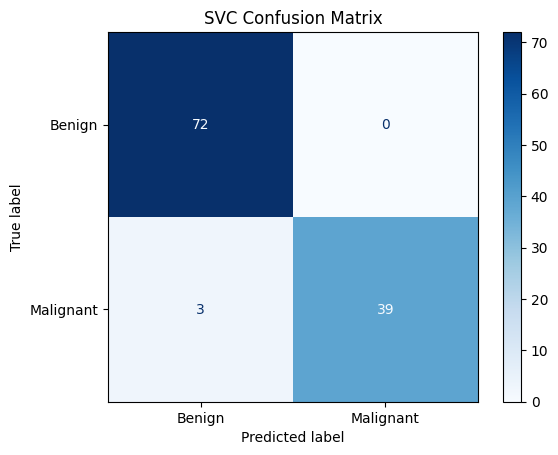

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_class, y_pred_class)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign', 'Malignant']
)

disp.plot(cmap='Blues')

plt.title('SVC Confusion Matrix')

plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.001, 0.0001],
    'kernel': ['rbf', 'linear']
}

grid_search = GridSearchCV(
    SVC(),
    param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_search.fit(
    X_train_class_scaled,
    y_train_class
)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Recall:", grid_search.best_score_)

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Recall: 0.9588235294117646


              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



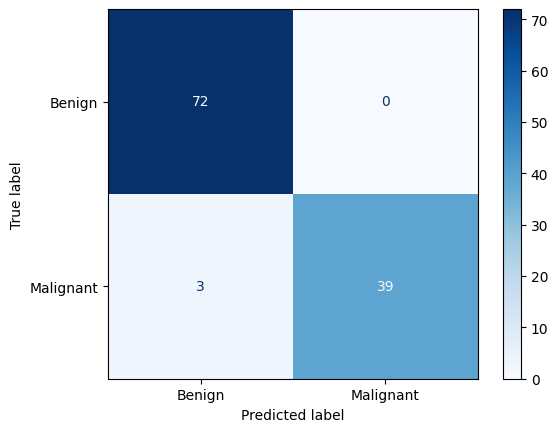

In [ ]:
best_svc = grid_search.best_estimator_

y_pred_tuned = best_svc.predict(X_test_class_scaled)

print(classification_report(
    y_test_class,
    y_pred_tuned,
    target_names=['Benign', 'Malignant']
))

cm_tuned = confusion_matrix(
    y_test_class,
    y_pred_tuned
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=['Benign', 'Malignant']
).plot(cmap='Blues')

plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.001, 0.0001],
    'kernel': ['rbf', 'linear']
}

grid_search = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_search.fit(
    X_train_class_scaled,
    y_train_class
)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Recall:", grid_search.best_score_)

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Recall: 0.9588235294117646


In [ ]:
best_svc = grid_search.best_estimator_

y_pred_tuned = best_svc.predict(X_test_class_scaled)

print("Tuned Accuracy:",
      accuracy_score(y_test_class, y_pred_tuned))

print("\nTuned Classification Report:")

print(classification_report(
    y_test_class,
    y_pred_tuned,
    target_names=['Benign', 'Malignant']
))

Tuned Accuracy: 0.9736842105263158

Tuned Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

